# 1. K-Means Clustering

**1.1 Dataset Generation**

In [ ]:
# Importing necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
# necessary configurations
num_points_per_semicircle = 500
radius = 1.0
center1 = (0.0, 0.0)
center2 = (1.0, 0.0)

In [ ]:
# generating theta
theta = np.linspace(0, np.pi, num_points_per_semicircle)

# setting random seed
np.random.seed(123)

In [ ]:
# generating first semi-circle (centered at (0,0))
semicircle1_x_ideal = center1[0] + radius * np.cos(theta)
semicircle1_y_ideal = center1[1] + radius * np.sin(theta)

# generating noise with mean 0 and standard deviation 0.1
noise_x1 = np.random.normal(loc = 0.0, scale = 0.1, size = semicircle1_x_ideal.shape)
noise_y1 = np.random.normal(loc = 0.0, scale = 0.1, size = semicircle1_y_ideal.shape)

# adding noise to the ideal coordinates
semicircle1_x = semicircle1_x_ideal + noise_x1
semicircle1_y = semicircle1_y_ideal + noise_y1

The parameterized coordinates of any point on the circumference of a circle with center(a, b) and radius
r are of the form (a + r cos , b + r sin ) for some   [0, 2].

In [ ]:
# generating second semi-circle (centered at (1,0))
semicircle2_x_ideal = center2[0] + radius * np.cos(theta)
semicircle2_y_ideal = center2[1] - radius * np.sin(theta) # -ve here, since this is this semicircle face upwards

# generating noise with mean 0 and standard deviation 0.1
noise_x2 = np.random.normal(loc = 0.0, scale = 0.1, size = semicircle2_x_ideal.shape)
noise_y2 = np.random.normal(loc = 0.0, scale = 0.1, size = semicircle2_y_ideal.shape)

# adding noise to the ideal coordinates
semicircle2_x = semicircle2_x_ideal + noise_x2
semicircle2_y = semicircle2_y_ideal + noise_y2

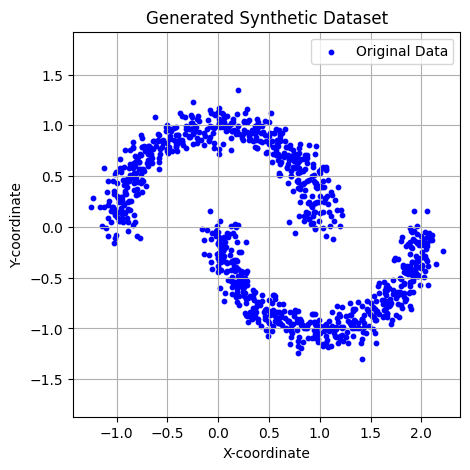

In [ ]:
# Plotting the points
plt.figure(figsize = (5, 5))
all_x = np.concatenate((semicircle1_x, semicircle2_x))
all_y = np.concatenate((semicircle1_y, semicircle2_y))
plt.scatter(all_x, all_y, color = 'blue', s = 10, label = 'Original Data')
plt.title('Generated Synthetic Dataset')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

In [ ]:
# storing data points
d1 = [(x, y) for x, y in zip(semicircle1_x, semicircle1_y)]
d2 = [(x, y) for x, y in zip(semicircle2_x, semicircle2_y)]
data_points = d1 + d2

**1.2 KMeans Clustering**

In [ ]:
# some configurations
k = 2
max_iters = 10000

# converting data points list of tuples to a numpy array for efficient calculations
data_points_np = np.array(data_points)
n_point = len(data_points)

In [ ]:
# 1.Initialization step
print("K-means clustering- 1.step initilization started ....")
x_min, x_max = -2.0, 3.0
y_min, y_max = -2.0, 2.0
initial_centroids = []
for i in range(k):
  cx = np.random.uniform(low = x_min, high = x_max)
  cy = np.random.uniform(low = y_min, high = y_max)
  initial_centroids.append(np.array([cx, cy]))
centroids = [initial_centroids[0], initial_centroids[1]]
c_1 = initial_centroids[0]
c_2 = initial_centroids[1]
print(f"  Initial Centroids: C_1 = {c_1}, C_2 = {c_2}")

K-means clustering- 1.step initilization started ....
  Initial Centroids: C_1 = [ 0.05518773 -0.52552776], C_2 = [1.45001574 0.9676345 ]


In [ ]:
# 2.Iteration and updation step
print("\nK-means clustering- iteration and updation started ....")
mappings = {point_tuple: -1 for point_tuple in data_points}
num_points_updated = n_point
current_iters = 0
def squared_euclidean_distance(p1, p2):
    return np.sum((p1 - p2)**2)
while num_points_updated > 0 and current_iters < max_iters:
    print(f"\nStarting Iteration {current_iters + 1}...")
    num_points_updated_this_iter = 0

    points_in_cluster = {0: [], 1: []}

    # Assigning each point in the dictionary to one of the two clusters.
    print(f"  Assigning points...")
    for i, point_tuple in enumerate(data_points):
        point_np = data_points_np[i]

        # Checking the point's Euclidean distance from each of the two centroids
        dist_to_c1 = squared_euclidean_distance(point_np, centroids[0])
        dist_to_c2 = squared_euclidean_distance(point_np, centroids[1])

        # Assigning the cluster corresponding to the nearest centroid
        nearest_cluster_index = 0 if dist_to_c1 < dist_to_c2 else 1

        # Keeping track of the number of points whose clusters were updated.
        previous_cluster = mappings[point_tuple]
        if previous_cluster != nearest_cluster_index:
            num_points_updated_this_iter += 1
            mappings[point_tuple] = nearest_cluster_index

        # Adding the point (np array) to the list for its assigned cluster
        points_in_cluster[nearest_cluster_index].append(point_np)

    # Updating the count for the stopping condition
    num_points_updated = num_points_updated_this_iter
    print(f"  Points whose cluster project changed in this iteration: {num_points_updated}")

    # Check stopping condition *before* updating centroids
    if num_points_updated == 0:
        print("\nConvergence reached: No points changed cluster project.")
        break

    # Updating the centroid values.
    print(f"  Updating centroids...")
    new_centroids = []
    for cluster_index in range(k):
        cluster_points_list = points_in_cluster[cluster_index]
        num_points_in_cluster = len(cluster_points_list)

        if num_points_in_cluster > 0:
            cluster_points_np = np.array(cluster_points_list)
            new_centroid = np.mean(cluster_points_np, axis=0)
            new_centroids.append(new_centroid)
            print(f"    New centroid for Cluster {cluster_index + 1} (based on {num_points_in_cluster} points): {new_centroid}")
        else:
            print(f"    Warning: Cluster {cluster_index + 1} has no points! Keeping previous centroid {centroids[cluster_index]}.")
            new_centroids.append(centroids[cluster_index])

    # Updating the main centroids list for the next iteration
    centroids = new_centroids
    current_iters += 1


K-means clustering- iteration and updation started ....

Starting Iteration 1...
  Assigning points...
  Points whose cluster allocation changed in this iteration: 1000
  Updating centroids...
    New centroid for Cluster 1 (based on 633 points): [ 0.18997292 -0.20420741]
    New centroid for Cluster 2 (based on 367 points): [1.03759032 0.34086455]

Starting Iteration 2...
  Assigning points...
  Points whose cluster allocation changed in this iteration: 105
  Updating centroids...
    New centroid for Cluster 1 (based on 544 points): [-0.0341203  -0.09129751]
    New centroid for Cluster 2 (based on 456 points): [1.1394955  0.09978036]

Starting Iteration 3...
  Assigning points...
  Points whose cluster allocation changed in this iteration: 162
  Updating centroids...
    New centroid for Cluster 1 (based on 520 points): [-0.18587681  0.21621375]
    New centroid for Cluster 2 (based on 480 points): [ 1.2452176  -0.24291074]

Starting Iteration 4...
  Assigning points...
  Points wh

In [ ]:
# Checking if loop terminated due to max iterations
if current_iters == max_iters:
    print(f"\nK-Means stopped after reaching the maximum number of iterations ({max_iters}).")
else:
    print(f"\nK-Means algorithm converged after {current_iters} iterations.")

print(f"Final Centroid C_1 (Index 0): {centroids[0]}")
print(f"Final Centroid C_2 (Index 1): {centroids[1]}")


K-Means algorithm converged after 10 iterations.
Final Centroid C_1 (Index 0): [-0.1331431   0.56481179]
Final Centroid C_2 (Index 1): [ 1.14546901 -0.58232085]


Plotting the clusters


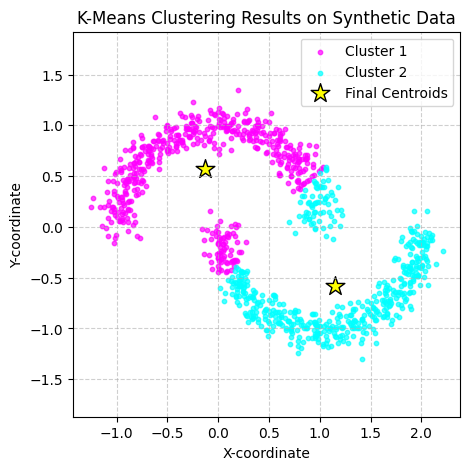


K-Means clustering and plotting complete.


In [ ]:
# Plotting the clusters
print("Plotting the clusters")

# separating the original data points based on their final cluster project
final_cluster_points = {0: [], 1: []}
for point_tuple, cluster_index in mappings.items():
    if cluster_index in final_cluster_points:
        final_cluster_points[cluster_index].append(point_tuple)
    else:
        print(f"Warning: Point {point_tuple} has invalid cluster index {cluster_index}")

plt.figure(figsize=(5, 5))
colors = ['magenta', 'cyan']
cluster_labels = ['Cluster 1', 'Cluster 2']

# plotting points for each cluster
for cluster_index in range(k):
    points_to_plot = final_cluster_points[cluster_index]
    if not points_to_plot:
        print(f"Plotting: Cluster {cluster_index+1} is empty.")
        continue

    points_np = np.array(points_to_plot)
    plt.scatter(points_np[:, 0], points_np[:, 1], s=10, color=colors[cluster_index], label=cluster_labels[cluster_index],alpha=0.7)


# plotting the final centroids
final_centroids_np = np.array(centroids)
plt.scatter(final_centroids_np[:, 0], final_centroids_np[:, 1], s=200, color='yellow', marker='*', edgecolors='black', linewidth=1,label='Final Centroids')

plt.title('K-Means Clustering Results on Synthetic Data')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.legend()
plt.show()
print("\nK-Means clustering and plotting complete.")

some comments -> *above is not expected result because while K-Means is a simple and often effective algorithm, its reliance on centroids and Euclidean distance minimization makes it unsuitable for discovering clusters with non-convex shapes like the interlocking semi-circles. To get the expected correct output we need to use Density-based algorithms like DBSCAN are designed to handle such structures more effectively.*

# 2. KMeans++ Clustering on the Covertype Dataset

In [1]:
# importing necessary libraries
import numpy as np
from sklearn.datasets import fetch_covtype
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

**2.1 Data Preparation**

In [49]:
# loading the dataset
covtype = fetch_covtype()
X_full = covtype['data']
y_full = covtype['target']

In [59]:
# creating subsamples 20000 observations with seed 42
rng_subsample = np.random.default_rng(42)
indices = rng_subsample.choice(X_full.shape[0], size=20000, replace=False)
X = X_full[indices]
y_subsampled = y_full[indices]


In [52]:
# standardizing the first 10 quantitative features
scaler = StandardScaler()
X_quant = scaler.fit_transform(X[:, :10])
X_bin = X[:, 10:]  # keeping binary features unchanged
X_std = np.hstack([X_quant, X_bin])  # final standardized data for clustering
print(f"the prepared data matrix X_std is with shape: {X_std.shape}")

the prepared data matrix X_std is with shape: (20000, 54)


**2.2 Implementing KMeans++**

In [53]:
# function for kmeans_plus_plus_init
def kmeans_plus_plus_init(X_data, k, seed=None):
    n_samples = X_data.shape[0]
    rng_init = np.random.default_rng(seed)

    centroids = []
    # the first centroid is random
    idx = rng_init.integers(n_samples)
    centroids.append(X_data[idx])

    # subsequent centroids
    for _ in range(1, k):
        # calculating squared distances to nearest chosen centroid for all points
        dists = np.array([min(np.sum((x - c)**2) for c in centroids)
                         for x in X_data])

        # Checking for zero distances sum
        dists_sum = dists.sum()
        if dists_sum <= 0:
            probs = np.ones(n_samples) / n_samples
        else:
            probs = dists / dists_sum

        idx = rng_init.choice(n_samples, p=probs)
        centroids.append(X_data[idx])

    return np.array(centroids)

In [60]:
# function for run_kmeans
def run_kmeans(X_data, k, init_centroids, max_iters=500):
    centroids = init_centroids.copy()
    n_samples = X_data.shape[0]
    # here we are initializing the labels to -1 to make ensure the first check fails if k=0 or similar corner cases
    labels = np.full(n_samples, -1, dtype=int)

    for iteration in range(max_iters):
        distances = np.linalg.norm(X_data[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        new_labels = np.argmin(distances, axis=1)

        # checking convergence
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # updating centroids
        new_centroids = np.empty_like(centroids)
        for i in range(k):
            cluster_points = X_data[labels == i]
            if len(cluster_points) == 0:
                local_rng = np.random.default_rng()
                new_centroids[i] = X_data[local_rng.integers(n_samples)]
                print(f"Warning: Cluster {i} empty, re-initializing centroid.")
            else:
                new_centroids[i] = cluster_points.mean(axis=0)
        centroids = new_centroids
    else:
         pass

    return centroids, labels


In [55]:
# running k-means++ with k=7
k_run = 7
init_centroids_pp = kmeans_plus_plus_init(X_std, k_run, seed=42)
final_centroids_pp, final_labels_pp = run_kmeans(X_std, k_run, init_centroids_pp)
print(f"K-Means++ run complete for k={k_run} and the final centroids shape: {final_centroids_pp.shape}")

K-Means++ run complete for k=7 and the final centroids shape: (7, 54)


**2.3 Evaluation and Visualisation**

In [56]:
# function for within_cluster_ssd
def within_cluster_ssd(X_data, centroids, labels):
    # checking if centroids or labels are empty or invalid
    if centroids is None or len(centroids) == 0 or labels is None:
        return np.inf
    k_local = centroids.shape[0]
    total_wcssd = 0
    for i in range(k_local):
        cluster_points = X_data[labels == i]
        if len(cluster_points) > 0:
            if i < len(centroids):
                 c = centroids[i]
                 total_wcssd += np.sum((cluster_points - c)**2)
    return total_wcssd

In [57]:
# function for random_init
def random_init(X_data, k, seed=None):
    rng_ri = np.random.default_rng(seed)
    n_samples = X_data.shape[0]
    indices = rng_ri.choice(n_samples, size=k, replace=False)
    return X_data[indices]

In [61]:
# 1.comparing K-Means++ run with random initialization baseline
print("\n1.Comparing WC-SSD (K-Means++ vs Random Init baseline):")
pp_wcssd = within_cluster_ssd(X_std, final_centroids_pp, final_labels_pp)
print(f"   K-Means++ WC-SSD (k=7): {pp_wcssd:.2f}")

# k = 7 and seed = 42
init_centroids_rnd = random_init(X_std, k_run)
final_centroids_rnd, final_labels_rnd = run_kmeans(X_std, k_run, init_centroids_rnd)
random_wcssd = within_cluster_ssd(X_std, final_centroids_rnd, final_labels_rnd)
print(f"   Random Init WC-SSD (k=7): {random_wcssd:.2f}")
print("\n   some comments:")
print(f"   K-Means++ initialization resulted in a lower WC-SSD ({pp_wcssd:.2f}) compared to")
print(f"   random initialization ({random_wcssd:.2f}), indicating that it found a more compact clustering.")


1.Comparing WC-SSD (K-Means++ vs Random Init baseline):
   K-Means++ WC-SSD (k=7): 127998.45
   Random Init WC-SSD (k=7): 129051.44

   some comments:
   K-Means++ initialization resulted in a lower WC-SSD (127998.45) compared to
   random initialization (129051.44), indicating that it found a more compact clustering.


In [62]:
# 2. making elbow method analysis
print("\nRunning K-Means++ for K=1..20 (10 runs each and ")
print("Running Random Init K-Means for K=1..20 (10 runs each")
K_range = range(1, 21)
n_runs = 10
pp_results = {k_val: [] for k_val in K_range}
random_results = {k_val: [] for k_val in K_range}

for k_val in tqdm(K_range, desc="Calculating Elbow Curve"):
    print(f"   Processing K={k_val}:")
    for run_idx in range(n_runs):
        pp_init = kmeans_plus_plus_init(X_std, k_val, seed=None)
        pp_centroids, pp_labels = run_kmeans(X_std, k_val, pp_init)
        pp_wcssd_run = within_cluster_ssd(X_std, pp_centroids, pp_labels)
        pp_results[k_val].append(pp_wcssd_run)

        rnd_init = random_init(X_std, k_val, seed=None)
        rnd_centroids, rnd_labels = run_kmeans(X_std, k_val, rnd_init)
        rnd_wcssd_run = within_cluster_ssd(X_std, rnd_centroids, rnd_labels)
        random_results[k_val].append(rnd_wcssd_run)


Running K-Means++ for K=1..20 (10 runs each and 
Running Random Init K-Means for K=1..20 (10 runs each


Calculating Elbow Curve:   0%|          | 0/20 [00:00<?, ?it/s]

   Processing K=1:
   Processing K=2:
   Processing K=3:
   Processing K=4:
   Processing K=5:
   Processing K=6:
   Processing K=7:
   Processing K=8:
   Processing K=9:
   Processing K=10:
   Processing K=11:
   Processing K=12:
   Processing K=13:
   Processing K=14:
   Processing K=15:
   Processing K=16:
   Processing K=17:
   Processing K=18:
   Processing K=19:
   Processing K=20:


In [63]:
# calculating the means
pp_means = [np.mean(pp_results[k_val]) for k_val in K_range]
random_means = [np.mean(random_results[k_val]) for k_val in K_range]

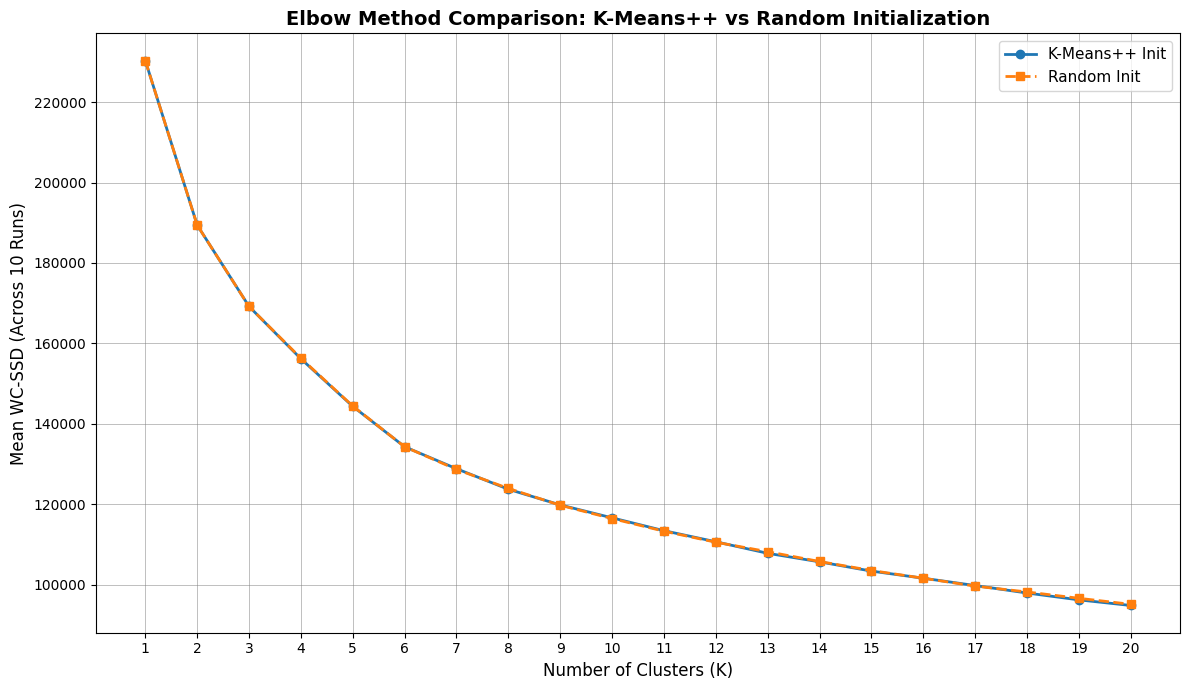

In [64]:
# plotting the results
plt.figure(figsize=(12, 7))

# plotting K-Means++ results
plt.plot(K_range, pp_means,marker='o',markersize=6,linestyle='-',linewidth=2,color='tab:blue',label='K-Means++ Init')

# plotting Random Init results
plt.plot(K_range, random_means,marker='s',markersize=6,linestyle='--', linewidth=2,color='tab:orange',label='Random Init')

plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Mean WC-SSD (Across 10 Runs)', fontsize=12)
plt.title('Elbow Method Comparison: K-Means++ vs Random Initialization', fontsize=14, fontweight='bold')
plt.xticks(list(K_range))
plt.yticks(fontsize=10)

plt.grid(True, which='major', linestyle='-', linewidth='0.5', color='gray', alpha=0.7)
plt.grid(True, which='minor', linestyle=':', linewidth='0.5', color='lightgray', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [65]:
# some comments
print("\nsome comments on Elbow Method:")
print("   the plot shows mean WC-SSD vs K. The 'elbow' point, where the rate of decrease")
print("   slows significantly, suggests a potential optimal K. For this dataset, a sharp elbow")
print("   is not clearly visible, possibly indicating non-spherical clusters or difficulty")
print("   in determining K solely based on WC-SSD.")

print("\nsome comments on differences:")
print("   the K-Means++ initialization line is consistently below the Random initialization line,")
print("   showing that K-Means++ yields lower average WC-SSD (more compact clusters)")
print("   across the range of K values tested compared to random starts.")


some comments on Elbow Method:
   the plot shows mean WC-SSD vs K. The 'elbow' point, where the rate of decrease
   slows significantly, suggests a potential optimal K. For this dataset, a sharp elbow
   is not clearly visible, possibly indicating non-spherical clusters or difficulty
   in determining K solely based on WC-SSD.

some comments on differences:
   the K-Means++ initialization line is consistently below the Random initialization line,
   showing that K-Means++ yields lower average WC-SSD (more compact clusters)
   across the range of K values tested compared to random starts.
